<a href="https://colab.research.google.com/github/Basugondal/Anamoly_detection/blob/main/Shop_Management.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi | head -15
import torch; print("GPU:", torch.cuda.is_available())


Mon Oct 19 05:54:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
WORK = "/content/drive/MyDrive/theft-ai"
!ls {WORK}

Mounted at /content/drive
DCSASS.zip


In [ ]:
!mkdir -p /content/dcsass
!unzip -q {WORK}/DCSASS.zip -d /content/dcsass
!find /content/dcsass -maxdepth 3 -type d | head -40
!find /content/dcsass -type f \( -name "*.mp4" -o -name "*.avi" \) | wc -l
!find /content/dcsass -type f \( -name "*.mp4" -o -name "*.avi" \) | head -5

/content/dcsass
/content/dcsass/DCSASS Dataset
/content/dcsass/DCSASS Dataset/DCSASS Dataset
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Explosion
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Fighting
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Robbery
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Shoplifting
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Labels
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Vandalism
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Abuse
/content/dcsass/DCSASS Dataset/DCSASS Dataset/RoadAccidents
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Burglary
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Assault
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Arrest
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Shooting
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Arson
/content/dcsass/DCSASS Dataset/DCSASS Dataset/Stealing
/content/dcsass/DCSASS Dataset/Explosion
/content/dcsass/DCSASS Dataset/Explosion/Explosion014_x264.mp4
/content/dcsass/DCSASS Dataset/Expl

In [ ]:

!pip -q install scikit-learn pandas opencv-python-headless onnx seaborn
import torch; print("GPU:", torch.cuda.is_available())


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 66.7 MB/s eta 0:00:00
GPU: True


In [ ]:
import glob, pandas as pd
BASE = "/content/dcsass/DCSASS Dataset/DCSASS Dataset"
files = sorted(glob.glob(f"{BASE}/Labels/*.csv"))
print(len(files), "label files:", [f.split("/")[-1] for f in files])
d = pd.read_csv(files[0], header=None)
print(d.head(5)); print(d.shape)

13 label files: ['Abuse.csv', 'Arrest.csv', 'Arson.csv', 'Assault.csv', 'Burglary.csv', 'Explosion.csv', 'Fighting.csv', 'RoadAccidents.csv', 'Robbery.csv', 'Shooting.csv', 'Shoplifting.csv', 'Stealing.csv', 'Vandalism.csv']
                 0      1    2
0  Abuse001_x264_0  Abuse  0.0
1  Abuse001_x264_1  Abuse  0.0
2  Abuse001_x264_2  Abuse  0.0
3  Abuse001_x264_3  Abuse  0.0
4  Abuse001_x264_4  Abuse  1.0
(1216, 3)


In [ ]:
import os, re, glob, pandas as pd

BASE = "/content/dcsass/DCSASS Dataset/DCSASS Dataset"

MAP = {  # anomalous clips (label 1) -> your class; other folders are skipped
    "Shoplifting": "shoplifting", "Stealing": "shoplifting",
    "Robbery": "robbery", "Burglary": "robbery",
    "Fighting": "fight", "Assault": "fight",
    "Arson": "emergency", "Explosion": "emergency", "Shooting": "emergency",
}

# index every clip file by name
paths = {}
for cls in os.listdir(BASE):
    d = f"{BASE}/{cls}"
    if cls == "Labels" or not os.path.isdir(d): continue
    for p in glob.glob(f"{d}/*/*.mp4"):
        paths[os.path.splitext(os.path.basename(p))[0]] = (p, cls)
print(len(paths), "clips indexed")

rows = []
for f in glob.glob(f"{BASE}/Labels/*.csv"):
    d = pd.read_csv(f, header=None, dtype=str)
    name_col = next(c for c in d.columns
                    if d[c].str.contains(r"_x264_\d+", na=False).mean() > 0.5)
    num_cols = [c for c in d.columns if c != name_col
                and pd.to_numeric(d[c], errors="coerce").isin([0, 1]).mean() > 0.9]
    lab_col = num_cols[-1]
    for name, lab in zip(d[name_col], d[lab_col]):
        name = re.sub(r"\.mp4$", "", str(name).strip())
        if name not in paths or pd.isna(pd.to_numeric(lab, errors="coerce")): continue
        p, folder = paths[name]
        if int(float(lab)) == 0:
            cls = "normal"
        else:
            cls = MAP.get(folder)
            if cls is None: continue
        rows.append((p, cls, re.sub(r"_\d+$", "", name)))

df = pd.DataFrame(rows, columns=["path", "label", "video"]).drop_duplicates("path")
print(df.label.value_counts(), "\n")
print("unique source videos:\n", df.groupby("label").video.nunique())

16639 clips indexed
label
normal         9500
robbery        2900
shoplifting    1120
emergency       776
fight           364
Name: count, dtype: int64 

unique source videos:
 label
emergency       70
fight           30
normal         507
robbery        146
shoplifting     84
Name: video, dtype: int64


In [ ]:
CAP_ABN, CAP_NORMAL = 1500, 3000
parts = []
for lab, g in df.groupby("label"):
    cap = CAP_NORMAL if lab == "normal" else CAP_ABN
    parts.append(g.sample(n=min(len(g), cap), random_state=42))
df = pd.concat(parts).reset_index(drop=True)
df.to_csv("/content/clips_raw.csv", index=False)
print(df.label.value_counts())

label
normal         3000
robbery        1500
shoplifting    1120
emergency       776
fight           364
Name: count, dtype: int64


In [ ]:
import os, pandas as pd
print(os.path.exists("/content/clips_raw.csv"))
df = pd.read_csv("/content/clips_raw.csv")
print(len(df)); print(df.label.value_counts())

True
6760
label
normal         3000
robbery        1500
shoplifting    1120
emergency       776
fight           364
Name: count, dtype: int64


In [ ]:
import os, subprocess, pandas as pd
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

df = pd.read_csv("/content/clips_raw.csv")
os.makedirs("/content/small", exist_ok=True)

def conv(p):
    out = "/content/small/" + os.path.basename(p)
    if not os.path.exists(out):
        subprocess.run(["ffmpeg", "-loglevel", "quiet", "-y", "-i", p,
                        "-vf", "scale=-2:128", "-r", "10", "-an", out])
    return out

with ThreadPoolExecutor(4) as ex:
    df["path"] = list(tqdm(ex.map(conv, df.path), total=len(df)))

df.to_csv("/content/clips_small.csv", index=False)
print(len(df), "clips resized")
print(len(os.listdir("/content/small")), "files in /content/small")

  0%|          | 0/6760 [00:00<?, ?it/s]

6760 clips resized
6760 files in /content/small


In [ ]:
import os, cv2, pandas as pd
from tqdm.auto import tqdm

df = pd.read_csv("/content/clips_small.csv")
print("start:", len(df))

keep, bad = [], 0
for _, r in tqdm(df.iterrows(), total=len(df)):
    if not os.path.exists(r.path) or os.path.getsize(r.path) < 1000:
        bad += 1; continue
    c = cv2.VideoCapture(r.path)
    n = c.get(cv2.CAP_PROP_FRAME_COUNT)
    ok = c.isOpened(); c.release()
    if ok and n >= 16:
        keep.append(r)
    else:
        bad += 1

df = pd.DataFrame(keep).drop_duplicates("path").reset_index(drop=True)
print("removed:", bad, "| kept:", len(df))

# keep normal at most 3x the largest abnormal class
abn = df[df.label != "normal"]
nor = df[df.label == "normal"]
cap = 3 * abn.label.value_counts().max()
if len(nor) > cap:
    nor = nor.sample(n=cap, random_state=42)
df = pd.concat([abn, nor]).sample(frac=1, random_state=42).reset_index(drop=True)

df.to_csv("/content/clips.csv", index=False)
print(df.label.value_counts())
print(df.groupby("label").video.nunique().rename("source videos"))

start: 6760


  0%|          | 0/6760 [00:00<?, ?it/s]

removed: 3037 | kept: 3723
label
normal         1521
robbery         814
shoplifting     753
emergency       411
fight           224
Name: count, dtype: int64
label
emergency       38
fight           19
normal         252
robbery         80
shoplifting     56
Name: source videos, dtype: int64


In [ ]:
import os, cv2, pandas as pd
df = pd.read_csv("/content/clips_small.csv")

missing = sum(not os.path.exists(p) for p in df.path)
print("files in /content/small:", len(os.listdir("/content/small")), "| missing from CSV:", missing)

sample = df.sample(300, random_state=0)
frames = []
for p in sample.path:
    if not os.path.exists(p): continue
    c = cv2.VideoCapture(p); frames.append(int(c.get(cv2.CAP_PROP_FRAME_COUNT))); c.release()
s = pd.Series(frames)
print(s.describe())
print("under 16 frames:", (s < 16).mean().round(2), "| under 8:", (s < 8).mean().round(2))

files in /content/small: 6760 | missing from CSV: 0
count    300.000000
mean      23.066667
std       14.682671
min       12.000000
25%       12.000000
50%       22.000000
75%       32.000000
max      142.000000
dtype: float64
under 16 frames: 0.45 | under 8: 0.0


In [ ]:
import os, cv2, pandas as pd
from tqdm.auto import tqdm

df = pd.read_csv("/content/clips_small.csv")
print("start:", len(df))

keep, bad = [], 0
for _, r in tqdm(df.iterrows(), total=len(df)):
    if not os.path.exists(r.path) or os.path.getsize(r.path) < 1000:
        bad += 1; continue
    c = cv2.VideoCapture(r.path)
    n = c.get(cv2.CAP_PROP_FRAME_COUNT)
    ok = c.isOpened(); c.release()
    if ok and n >= 8:                 # was 16
        keep.append(r)
    else:
        bad += 1

df = pd.DataFrame(keep).drop_duplicates("path").reset_index(drop=True)
print("removed:", bad, "| kept:", len(df))

abn = df[df.label != "normal"]
nor = df[df.label == "normal"]
cap = 3 * abn.label.value_counts().max()
if len(nor) > cap:
    nor = nor.sample(n=cap, random_state=42)
df = pd.concat([abn, nor]).sample(frac=1, random_state=42).reset_index(drop=True)

df.to_csv("/content/clips.csv", index=False)
print(df.label.value_counts())
print(df.groupby("label").video.nunique().rename("source videos"))

start: 6760


  0%|          | 0/6760 [00:00<?, ?it/s]

removed: 0 | kept: 6760
label
normal         3000
robbery        1500
shoplifting    1120
emergency       776
fight           364
Name: count, dtype: int64
label
emergency       70
fight           30
normal         477
robbery        145
shoplifting     84
Name: source videos, dtype: int64


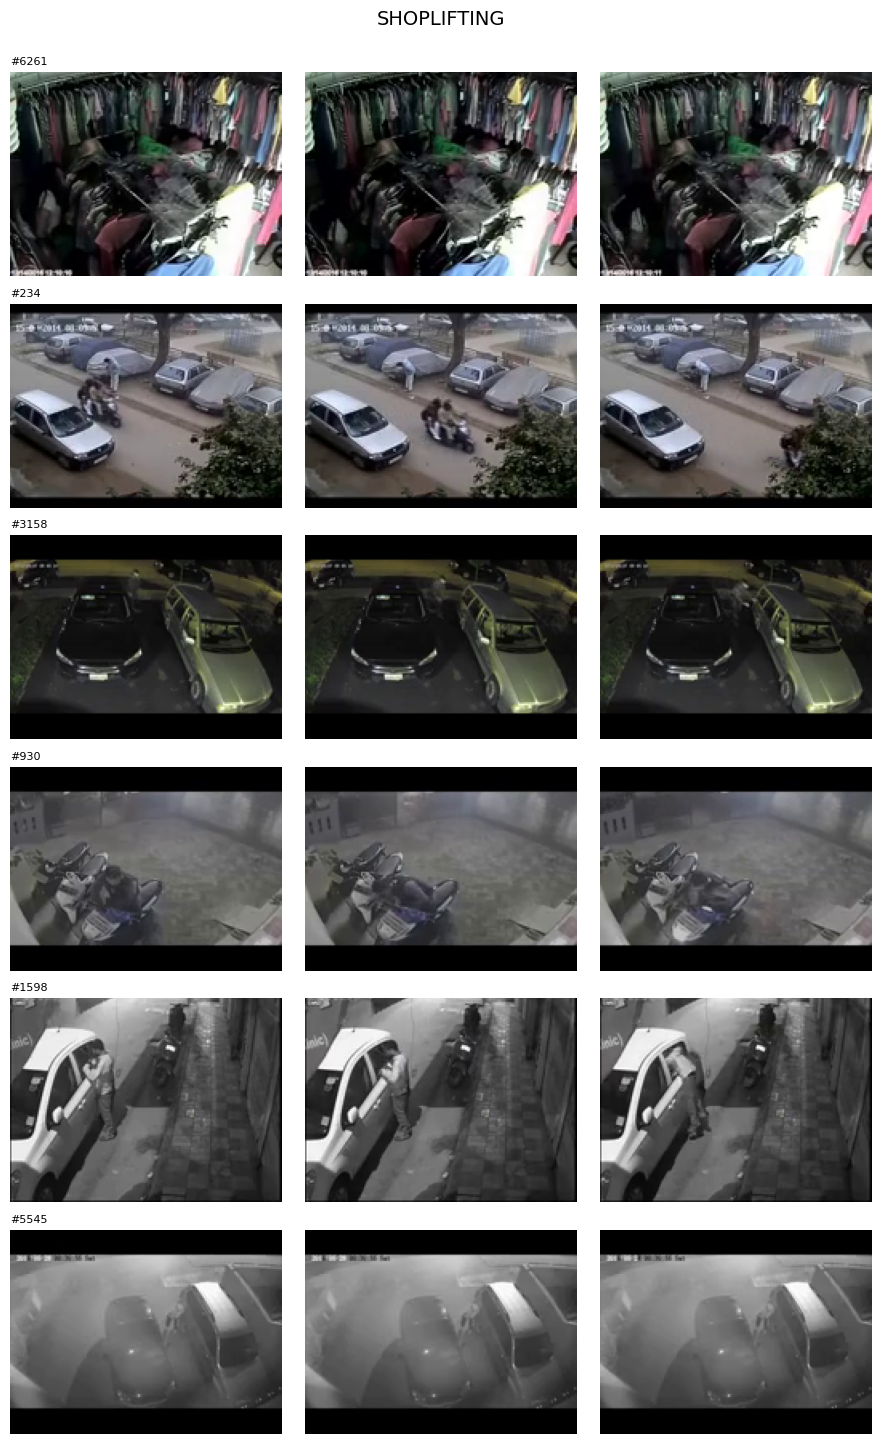

In [ ]:
import cv2, pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("/content/clips.csv")

def frame_at(c, k):
    c.set(cv2.CAP_PROP_POS_FRAMES, k)
    ok, f = c.read()
    return f[:, :, ::-1] if ok else None

def show(label, n=6, seed=1):
    sample = df[df.label == label].sample(n, random_state=seed)
    fig, axes = plt.subplots(n, 3, figsize=(9, 2.4 * n))
    fig.suptitle(f"{label.upper()}", fontsize=14, y=1.0)
    for row, (_, r) in zip(axes, sample.iterrows()):
        c = cv2.VideoCapture(r.path)
        total = int(c.get(cv2.CAP_PROP_FRAME_COUNT))
        for ax, k in zip(row, [0, total // 2, total - 1]):
            img = frame_at(c, k)
            if img is not None: ax.imshow(img)
            ax.axis("off")
        row[0].set_title(f"#{_}", fontsize=8, loc="left")
        c.release()
    plt.tight_layout(); plt.show()

show("shoplifting")

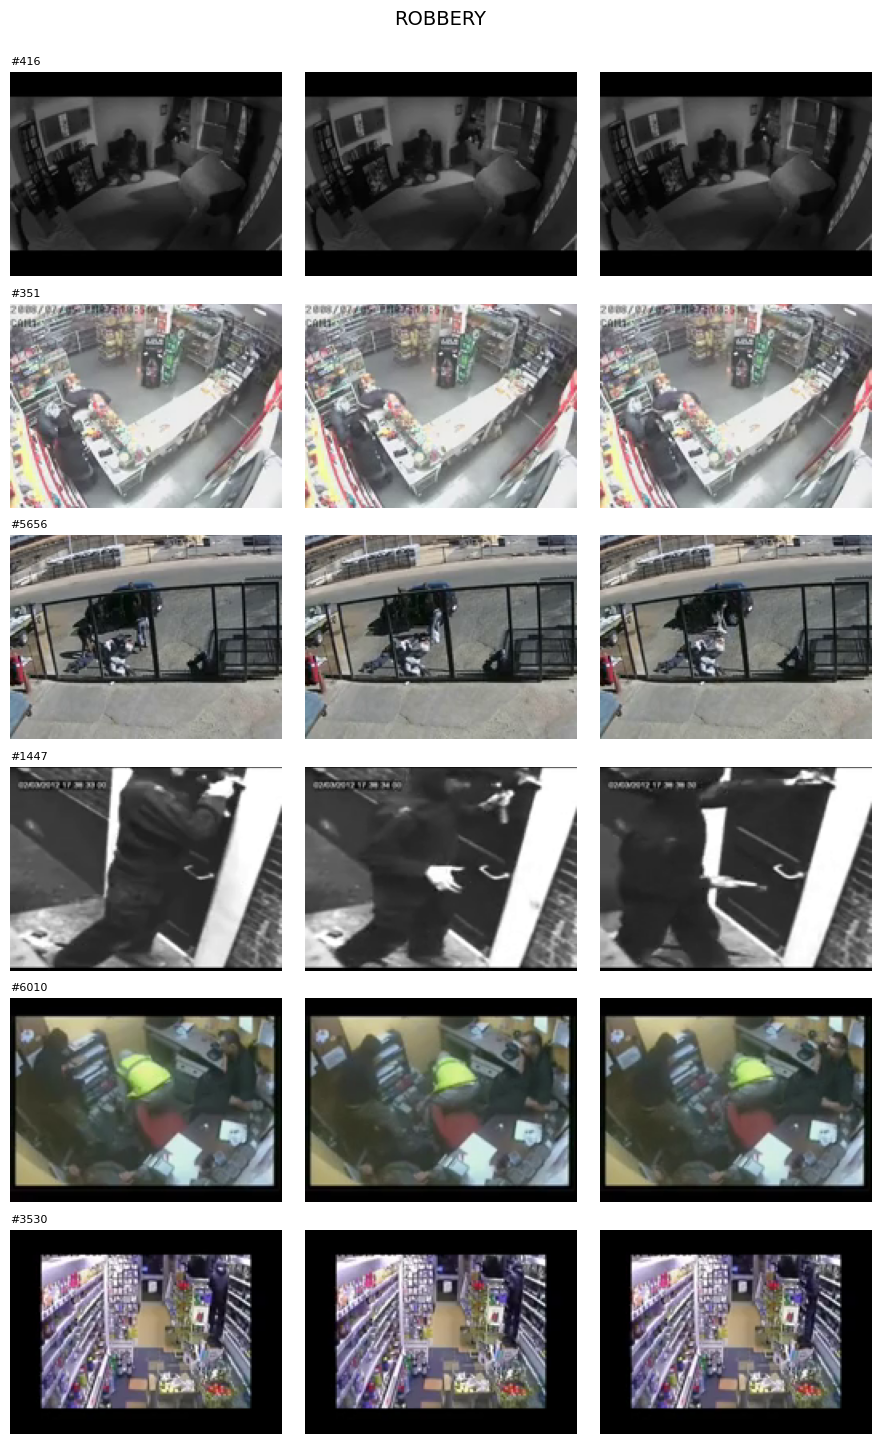

In [ ]:
import cv2, pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("/content/clips.csv")

def frame_at(c, k):
    c.set(cv2.CAP_PROP_POS_FRAMES, k)
    ok, f = c.read()
    return f[:, :, ::-1] if ok else None

def show(label, n=6, seed=1):
    sample = df[df.label == label].sample(n, random_state=seed)
    fig, axes = plt.subplots(n, 3, figsize=(9, 2.4 * n))
    fig.suptitle(f"{label.upper()}", fontsize=14, y=1.0)
    for row, (_, r) in zip(axes, sample.iterrows()):
        c = cv2.VideoCapture(r.path)
        total = int(c.get(cv2.CAP_PROP_FRAME_COUNT))
        for ax, k in zip(row, [0, total // 2, total - 1]):
            img = frame_at(c, k)
            if img is not None: ax.imshow(img)
            ax.axis("off")
        row[0].set_title(f"#{_}", fontsize=8, loc="left")
        c.release()
    plt.tight_layout(); plt.show()

show("robbery")

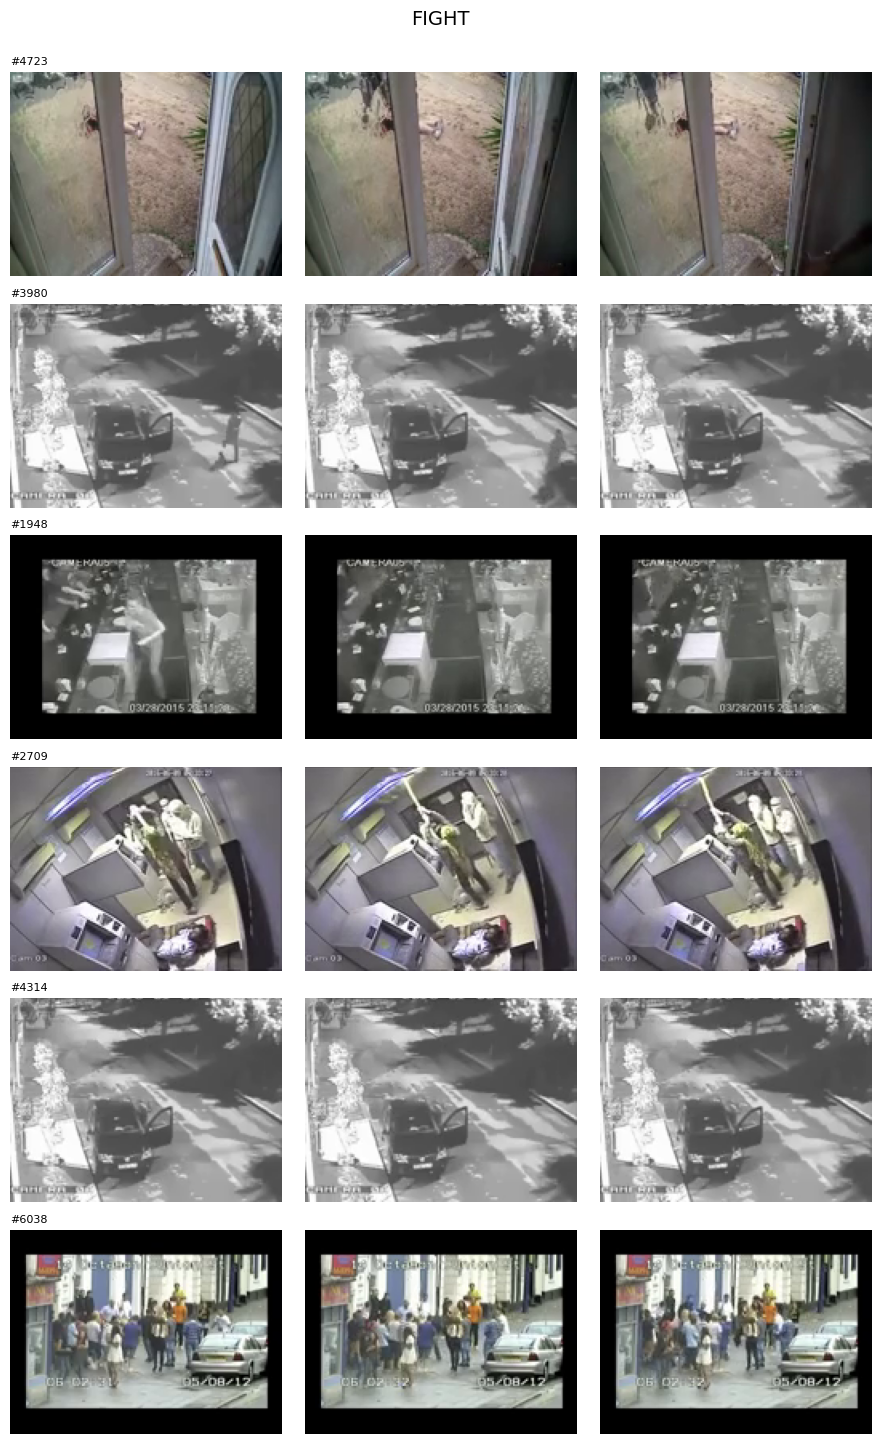

In [ ]:

import cv2, pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("/content/clips.csv")

def frame_at(c, k):
    c.set(cv2.CAP_PROP_POS_FRAMES, k)
    ok, f = c.read()
    return f[:, :, ::-1] if ok else None

def show(label, n=6, seed=1):
    sample = df[df.label == label].sample(n, random_state=seed)
    fig, axes = plt.subplots(n, 3, figsize=(9, 2.4 * n))
    fig.suptitle(f"{label.upper()}", fontsize=14, y=1.0)
    for row, (_, r) in zip(axes, sample.iterrows()):
        c = cv2.VideoCapture(r.path)
        total = int(c.get(cv2.CAP_PROP_FRAME_COUNT))
        for ax, k in zip(row, [0, total // 2, total - 1]):
            img = frame_at(c, k)
            if img is not None: ax.imshow(img)
            ax.axis("off")
        row[0].set_title(f"#{_}", fontsize=8, loc="left")
        c.release()
    plt.tight_layout(); plt.show()
show("fight")

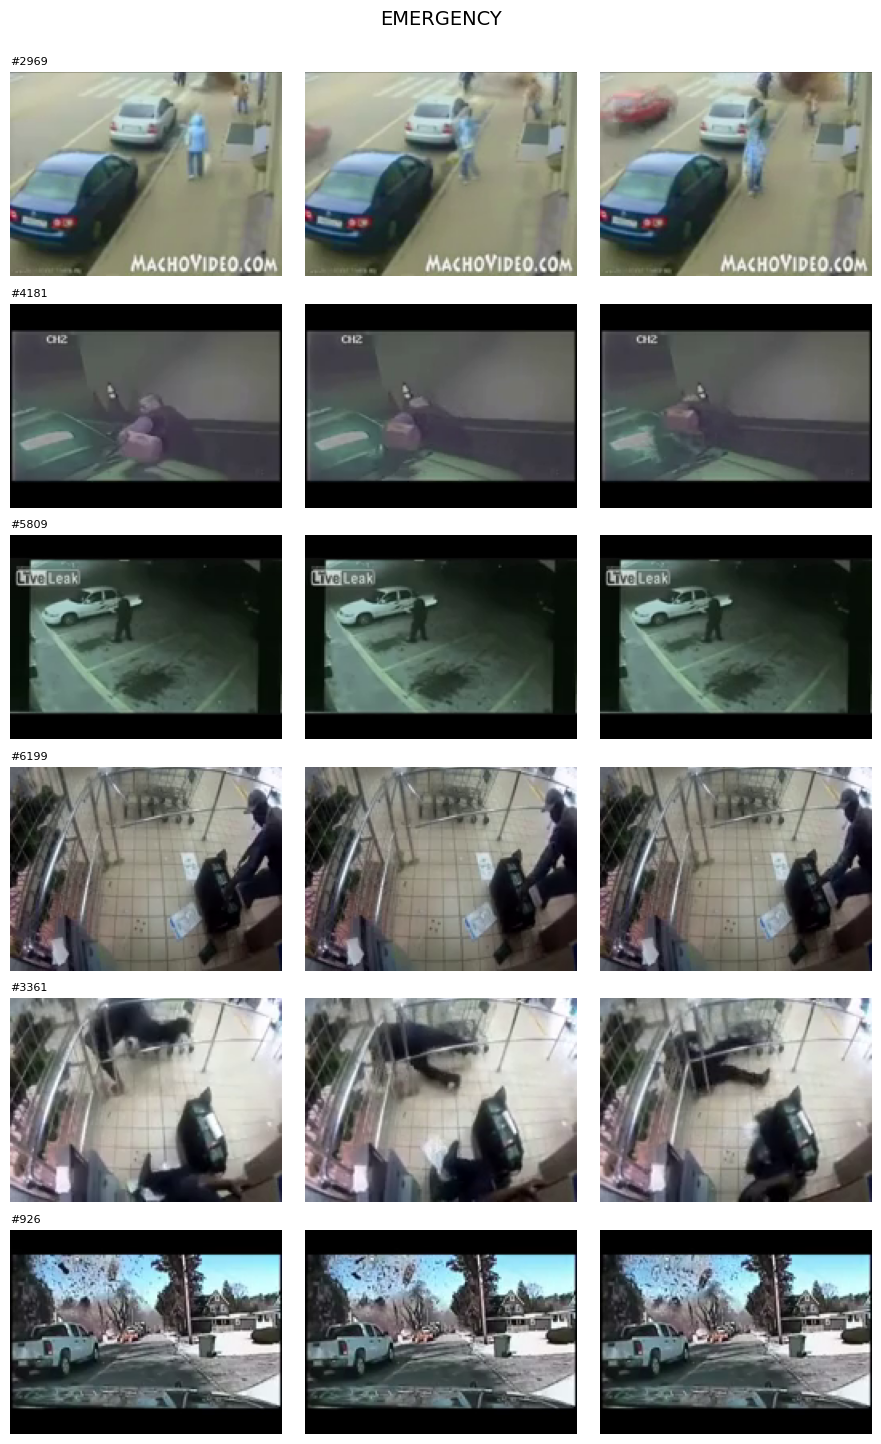

In [ ]:
import cv2, pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("/content/clips.csv")

def frame_at(c, k):
    c.set(cv2.CAP_PROP_POS_FRAMES, k)
    ok, f = c.read()
    return f[:, :, ::-1] if ok else None

def show(label, n=6, seed=1):
    sample = df[df.label == label].sample(n, random_state=seed)
    fig, axes = plt.subplots(n, 3, figsize=(9, 2.4 * n))
    fig.suptitle(f"{label.upper()}", fontsize=14, y=1.0)
    for row, (_, r) in zip(axes, sample.iterrows()):
        c = cv2.VideoCapture(r.path)
        total = int(c.get(cv2.CAP_PROP_FRAME_COUNT))
        for ax, k in zip(row, [0, total // 2, total - 1]):
            img = frame_at(c, k)
            if img is not None: ax.imshow(img)
            ax.axis("off")
        row[0].set_title(f"#{_}", fontsize=8, loc="left")
        c.release()
    plt.tight_layout(); plt.show()

show("emergency")

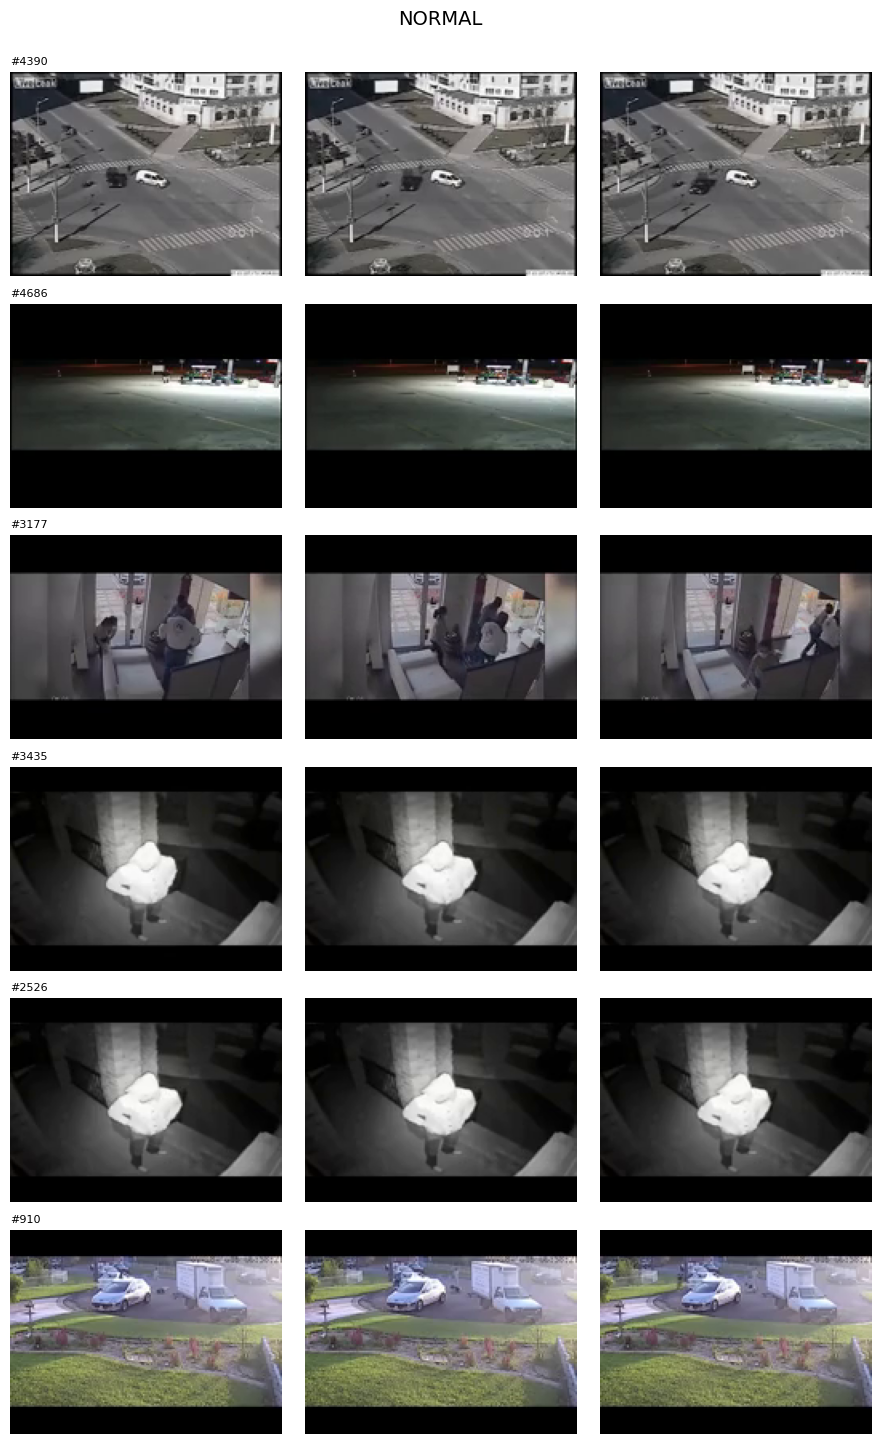

In [ ]:
import cv2, pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("/content/clips.csv")

def frame_at(c, k):
    c.set(cv2.CAP_PROP_POS_FRAMES, k)
    ok, f = c.read()
    return f[:, :, ::-1] if ok else None

def show(label, n=6, seed=1):
    sample = df[df.label == label].sample(n, random_state=seed)
    fig, axes = plt.subplots(n, 3, figsize=(9, 2.4 * n))
    fig.suptitle(f"{label.upper()}", fontsize=14, y=1.0)
    for row, (_, r) in zip(axes, sample.iterrows()):
        c = cv2.VideoCapture(r.path)
        total = int(c.get(cv2.CAP_PROP_FRAME_COUNT))
        for ax, k in zip(row, [0, total // 2, total - 1]):
            img = frame_at(c, k)
            if img is not None: ax.imshow(img)
            ax.axis("off")
        row[0].set_title(f"#{_}", fontsize=8, loc="left")
        c.release()
    plt.tight_layout(); plt.show()

show("normal")

In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

df = pd.read_csv("/content/clips.csv")
print("total:", len(df))

folds = list(StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
             .split(df, df.label, groups=df.video))
test_i, val_i = folds[0][1], folds[1][1]
train_i = sorted(set(range(len(df))) - set(test_i) - set(val_i))

df.iloc[train_i].to_csv("/content/train.csv", index=False)
df.iloc[val_i].to_csv("/content/val.csv", index=False)
df.iloc[test_i].to_csv("/content/test.csv", index=False)

for n in ["train", "val", "test"]:
    d = pd.read_csv(f"/content/{n}.csv")
    print(f"\n{n}: {len(d)} clips")
    print(pd.DataFrame({"clips": d.label.value_counts(),
                        "videos": d.groupby("label").video.nunique()}))

tr, va, te = [set(pd.read_csv(f"/content/{n}.csv").video) for n in ["train", "val", "test"]]
assert not (tr & va) and not (tr & te) and not (va & te), "video leakage!"
print("\nNo video appears in more than one split.")

total: 6760

train: 4487 clips
             clips  videos
label                     
emergency      479      47
fight          218      19
normal        2070     320
robbery        935      94
shoplifting    785      57

val: 1155 clips
             clips  videos
label                     
emergency      191      14
fight          125      10
normal         467      75
robbery        298      26
shoplifting     74       9

test: 1118 clips
             clips  videos
label                     
emergency      106       9
fight           21       1
normal         463      82
robbery        267      25
shoplifting    261      18

No video appears in more than one split.


In [ ]:
WORK = "/content/drive/MyDrive/theft-ai"
!mkdir -p {WORK}/models
!cp /content/clips.csv /content/train.csv /content/val.csv /content/test.csv {WORK}/
!cd /content && zip -qr {WORK}/small.zip small
!ls -lh {WORK}

total 1.5G
-rw------- 1 root root 425K Oct 19 07:04 clips.csv
-rw------- 1 root root 1.4G Oct 19 06:03 DCSASS.zip
drwx------ 2 root root 4.0K Oct 19 07:04 models
-rw------- 1 root root  85M Oct 19 07:04 small.zip
-rw------- 1 root root  71K Oct 19 07:04 test.csv
-rw------- 1 root root 282K Oct 19 07:04 train.csv
-rw------- 1 root root  72K Oct 19 07:04 val.csv


In [ ]:
import pandas as pd, itertools
from sklearn.model_selection import StratifiedGroupKFold

df = pd.read_csv("/content/clips.csv")
classes = sorted(df.label.unique())
vid_n = lambda idx: df.iloc[idx].groupby("label").video.nunique().reindex(classes, fill_value=0)

best, best_score = None, -1
for seed in range(300):
    folds = [f[1] for f in StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=seed)
             .split(df, df.label, groups=df.video)]
    for a, b in itertools.permutations(range(6), 2):      # a = test fold, b = val fold
        t, v = vid_n(folds[a]), vid_n(folds[b])
        score = min(t.min(), v.min())                      # weakest class in either split
        if t["fight"] >= 3 and v["fight"] >= 3 and score > best_score:
            best_score, best = score, (seed, a, b)

seed, a, b = best
print("best seed:", seed, "| test fold:", a, "| val fold:", b, "| min videos per class:", best_score)

folds = [f[1] for f in StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=seed)
         .split(df, df.label, groups=df.video)]
test_i, val_i = folds[a], folds[b]
train_i = sorted(set(range(len(df))) - set(test_i) - set(val_i))

for name, idx in [("train", train_i), ("val", val_i), ("test", test_i)]:
    df.iloc[idx].to_csv(f"/content/{name}.csv", index=False)
    d = df.iloc[idx]
    print(f"\n{name}: {len(d)} clips")
    print(pd.DataFrame({"clips": d.label.value_counts(), "videos": d.groupby("label").video.nunique()}))

tr, va, te = [set(pd.read_csv(f"/content/{n}.csv").video) for n in ["train", "val", "test"]]
assert not (tr & va) and not (tr & te) and not (va & te), "video leakage!"
print("\nNo video appears in more than one split.")

best seed: 265 | test fold: 3 | val fold: 5 | min videos per class: 10

train: 4415 clips
             clips  videos
label                     
emergency      537      49
fight          128      10
normal        2002     319
robbery       1042     102
shoplifting    706      56

val: 1177 clips
             clips  videos
label                     
emergency      119      11
fight          126      10
normal         522      79
robbery        239      25
shoplifting    171      11

test: 1168 clips
             clips  videos
label                     
emergency      120      10
fight          110      10
normal         476      79
robbery        219      18
shoplifting    243      17

No video appears in more than one split.


In [ ]:
WORK = "/content/drive/MyDrive/theft-ai"
!mkdir -p {WORK}/models
!cp /content/clips.csv /content/train.csv /content/val.csv /content/test.csv {WORK}/
!cd /content && zip -qr {WORK}/small.zip small
!ls -lh {WORK}

total 1.5G
-rw------- 1 root root 425K Oct 19 07:07 clips.csv
-rw------- 1 root root 1.4G Oct 19 06:03 DCSASS.zip
drwx------ 2 root root 4.0K Oct 19 07:04 models
-rw------- 1 root root  85M Oct 19 07:07 small.zip
-rw------- 1 root root  73K Oct 19 07:07 test.csv
-rw------- 1 root root 279K Oct 19 07:07 train.csv
-rw------- 1 root root  74K Oct 19 07:07 val.csv


In [ ]:
import os, cv2, torch, torch.nn as nn, numpy as np, pandas as pd
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision.models.video import r2plus1d_18, R2Plus1D_18_Weights
from sklearn.metrics import classification_report, confusion_matrix

T, H, W = 16, 112, 149
CLASSES = sorted(pd.read_csv("/content/train.csv").label.unique())
c2i = {c: i for i, c in enumerate(CLASSES)}
mean = torch.tensor([0.43216, 0.394666, 0.37645]).view(3, 1, 1, 1)
std = torch.tensor([0.22803, 0.22145, 0.216989]).view(3, 1, 1, 1)

def read_frames(path):
    cap, fr = cv2.VideoCapture(path), []
    while True:
        ok, f = cap.read()
        if not ok: break
        fr.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    cap.release()
    return fr

class VideoDS(Dataset):
    def __init__(self, csv, train):
        self.df, self.train = pd.read_csv(csv), train
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        fr = read_frames(r.path); n = len(fr)
        if self.train:
            idx = np.sort(np.random.randint(0, n, T))          # random temporal sampling
        else:
            idx = np.linspace(0, n - 1, T).astype(int)
        x = torch.from_numpy(np.stack([fr[j] for j in idx])).permute(3, 0, 1, 2).float() / 255  # C,T,h,w
        if self.train:
            _, _, h, w = x.shape
            s = np.random.uniform(0.7, 1.0); ch, cw = int(h * s), int(w * s)
            y0, x0 = np.random.randint(0, h - ch + 1), np.random.randint(0, w - cw + 1)
            x = x[:, :, y0:y0 + ch, x0:x0 + cw]                 # random crop
            if np.random.rand() < 0.5: x = x.flip(-1)           # horizontal flip
            if np.random.rand() < 0.2: x = x.mean(0, keepdim=True).repeat(3, 1, 1, 1)  # grayscale (night/IR)
            x = (x * np.random.uniform(0.7, 1.3) + 0.02 * torch.randn_like(x)).clamp(0, 1)  # brightness + noise
        x = nn.functional.interpolate(x, size=(H, W), mode="bilinear", align_corners=False)
        return (x - mean) / std, c2i[r.label]

train_ds = VideoDS("/content/train.csv", True)
labels = train_ds.df.label.map(c2i).values
sampler = WeightedRandomSampler(1.0 / np.bincount(labels)[labels], len(labels), replacement=True)

tr = DataLoader(train_ds, batch_size=8, sampler=sampler, num_workers=2, drop_last=True)
va = DataLoader(VideoDS("/content/val.csv", False), batch_size=8, num_workers=2)
te = DataLoader(VideoDS("/content/test.csv", False), batch_size=8, num_workers=2)

model = r2plus1d_18(weights=R2Plus1D_18_Weights.KINETICS400_V1)
model.fc = nn.Sequential(nn.Dropout(0.5), nn.Linear(512, len(CLASSES)))
model = model.cuda()

print("classes:", CLASSES)
print("train / val / test clips:", len(tr.dataset), len(va.dataset), len(te.dataset))

Downloading: "https://download.pytorch.org/models/r2plus1d_18-91a641e6.pth" to /root/.cache/torch/hub/checkpoints/r2plus1d_18-91a641e6.pth


100%|██████████| 120M/120M [00:00<00:00, 161MB/s]


classes: ['emergency', 'fight', 'normal', 'robbery', 'shoplifting']
train / val / test clips: 4415 1177 1168


In [ ]:
x, y = next(iter(tr))
print("batch:", x.shape, "labels:", y.tolist())
with torch.no_grad():
    out = model(x.cuda())
print("output:", out.shape)
print("GPU memory used (GB):", round(torch.cuda.max_memory_allocated() / 1e9, 2))

batch: torch.Size([8, 3, 16, 112, 149]) labels: [2, 2, 3, 4, 3, 4, 3, 4]
output: torch.Size([8, 5])
GPU memory used (GB): 1.19


In [ ]:
import os, torch, torch.nn as nn, numpy as np
from sklearn.metrics import classification_report, f1_score
from tqdm.auto import tqdm

WORK = "/content/drive/MyDrive/theft-ai"
os.makedirs(f"{WORK}/models", exist_ok=True)
BEST, LAST = f"{WORK}/models/best.pt", f"{WORK}/models/last.pt"

EPOCHS, FREEZE_UNTIL = 20, 5
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler = torch.cuda.amp.GradScaler()

def set_frozen(frozen):
    for n, p in model.named_parameters():
        if n.startswith(("stem", "layer1", "layer2")):
            p.requires_grad = not frozen

def evaluate(loader):
    model.eval(); P, Y = [], []
    with torch.no_grad():
        for x, y in loader:
            P += model(x.cuda()).argmax(1).cpu().tolist()
            Y += y.tolist()
    return Y, P

start, best_f1 = 0, 0.0
set_frozen(True)
opt = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-2)

if os.path.exists(LAST):                                   # resume after disconnect
    ck = torch.load(LAST)
    model.load_state_dict(ck["model"])
    start, best_f1 = ck["epoch"] + 1, ck["best_f1"]
    if start >= FREEZE_UNTIL:
        set_frozen(False)
        opt = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=1e-2)
    print(f"resumed from epoch {start}, best F1 so far {best_f1:.3f}")

for epoch in range(start, EPOCHS):
    if epoch == FREEZE_UNTIL:
        set_frozen(False)
        opt = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=1e-2)
        print("unfroze all layers")

    model.train(); total = 0
    for x, y in tqdm(tr, desc=f"epoch {epoch}", leave=False):
        x, y = x.cuda(), y.cuda()
        with torch.cuda.amp.autocast():
            loss = loss_fn(model(x), y)
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        total += loss.item()

    Y, P = evaluate(va)
    f1 = f1_score(Y, P, average="macro", zero_division=0)
    per = f1_score(Y, P, average=None, labels=range(len(CLASSES)), zero_division=0)
    print(f"epoch {epoch:2d} | loss {total/len(tr):.3f} | val macro-F1 {f1:.3f} | "
          + " ".join(f"{c[:5]} {s:.2f}" for c, s in zip(CLASSES, per)))

    if f1 > best_f1:
        best_f1 = f1
        torch.save({"model": model.state_dict(), "classes": CLASSES}, BEST)
        print("   saved best")
    torch.save({"model": model.state_dict(), "epoch": epoch, "best_f1": best_f1}, LAST)

/tmp/ipykernel_1432/3138150001.py:11: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


epoch 0:   0%|          | 0/551 [00:00<?, ?it/s]

/tmp/ipykernel_1432/3138150001.py:48: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


epoch  0 | loss 1.008 | val macro-F1 0.368 | emerg 0.35 fight 0.20 norma 0.46 robbe 0.48 shopl 0.36
   saved best


epoch 1:   0%|          | 0/551 [00:00<?, ?it/s]

...

/tmp/ipykernel_1432/3138150001.py:48: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8338dd5f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8338dd5f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 17

epoch  5 | loss 0.606 | val macro-F1 0.351 | emerg 0.36 fight 0.00 norma 0.62 robbe 0.51 shopl 0.27


epoch 6:   0%|          | 0/551 [00:00<?, ?it/s]

/tmp/ipykernel_1432/3138150001.py:48: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


KeyboardInterrupt: 

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report
model.load_state_dict(torch.load(BEST)["model"])
Y, P = evaluate(va)
print(classification_report(Y, P, labels=range(5), target_names=CLASSES, zero_division=0))
print(pd.DataFrame(confusion_matrix(Y, P, labels=range(5)), index=CLASSES, columns=CLASSES))

              precision    recall  f1-score   support

   emergency       0.45      0.61      0.52       119
       fight       0.00      0.00      0.00       126
      normal       0.57      0.66      0.61       522
     robbery       0.43      0.55      0.48       239
 shoplifting       0.60      0.38      0.47       171

    accuracy                           0.52      1177
   macro avg       0.41      0.44      0.42      1177
weighted avg       0.47      0.52      0.49      1177

             emergency  fight  normal  robbery  shoplifting
emergency           72      1      43        3            0
fight                2      0      48       68            8
normal              60      2     342       92           26
robbery             17      0      81      132            9
shoplifting          9      0      86       11           65


In [ ]:
from sklearn.metrics import classification_report
n = CLASSES.index("normal")
Yb = [int(y != n) for y in Y]; Pb = [int(p != n) for p in P]
print(classification_report(Yb, Pb, target_names=["normal", "abnormal"]))



              precision    recall  f1-score   support

      normal       0.57      0.66      0.61       522
    abnormal       0.69      0.61      0.64       655

    accuracy                           0.63      1177
   macro avg       0.63      0.63      0.63      1177
weighted avg       0.64      0.63      0.63      1177



In [ ]:
import warnings; warnings.filterwarnings("ignore")
for nm in ["train", "val", "test"]:
    d = pd.read_csv(f"/content/{nm}.csv")
    d["label"] = d.label.map(lambda x: "normal" if x == "normal" else "abnormal")
    d.to_csv(f"/content/{nm}2.csv", index=False)
    print(nm, d.label.value_counts().to_dict())

CLASSES = ["abnormal", "normal"]
c2i = {c: i for i, c in enumerate(CLASSES)}

train_ds = VideoDS("/content/train2.csv", True)
labels = train_ds.df.label.map(c2i).values
sampler = WeightedRandomSampler(1.0 / np.bincount(labels)[labels], len(labels), replacement=True)
tr = DataLoader(train_ds, batch_size=8, sampler=sampler, num_workers=2, drop_last=True)
va = DataLoader(VideoDS("/content/val2.csv", False), batch_size=8, num_workers=2)
te = DataLoader(VideoDS("/content/test2.csv", False), batch_size=8, num_workers=2)

model = r2plus1d_18(weights=R2Plus1D_18_Weights.KINETICS400_V1)
model.fc = nn.Sequential(nn.Dropout(0.5), nn.Linear(512, 2))
model = model.cuda()


train {'abnormal': 2413, 'normal': 2002}
val {'abnormal': 655, 'normal': 522}
test {'abnormal': 692, 'normal': 476}


In [35]:
import warnings; warnings.filterwarnings("ignore")
import os, torch, torch.nn as nn, numpy as np
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

WORK = "/content/drive/MyDrive/theft-ai"
os.makedirs(f"{WORK}/models", exist_ok=True)
BEST, LAST = f"{WORK}/models/best2.pt", f"{WORK}/models/last2.pt"

EPOCHS, FREEZE_UNTIL = 10, 2
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def set_frozen(frozen):
    for n, p in model.named_parameters():
        if n.startswith(("stem", "layer1", "layer2")):
            p.requires_grad = not frozen

def evaluate(loader):
    model.eval(); P, Y = [], []
    with torch.no_grad():
        for x, y in loader:
            P += model(x.cuda()).argmax(1).cpu().tolist()
            Y += y.tolist()
    return Y, P

start, best_f1 = 0, 0.0
set_frozen(True)
opt = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                        lr=1e-4, weight_decay=1e-2)

if os.path.exists(LAST):                                   # resume after a disconnect
    ck = torch.load(LAST)
    model.load_state_dict(ck["model"])
    start, best_f1 = ck["epoch"] + 1, ck["best_f1"]
    if start >= FREEZE_UNTIL:
        set_frozen(False)
        opt = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=1e-2)
    print(f"resumed from epoch {start}, best F1 so far {best_f1:.3f}")

for epoch in range(start, EPOCHS):
    if epoch == FREEZE_UNTIL:
        set_frozen(False)
        opt = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=1e-2)
        print("unfroze all layers")

    model.train(); total = 0
    for x, y in tqdm(tr, desc=f"epoch {epoch}", leave=False):
        x, y = x.cuda(), y.cuda()
        with torch.amp.autocast("cuda"):
            loss = loss_fn(model(x), y)
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        total += loss.item()

    Y, P = evaluate(va)
    f1 = f1_score(Y, P, average="macro", zero_division=0)
    per = f1_score(Y, P, average=None, labels=[0, 1], zero_division=0)
    print(f"epoch {epoch:2d} | loss {total/len(tr):.3f} | val macro-F1 {f1:.3f} | "
          f"abnormal {per[0]:.2f} normal {per[1]:.2f}")

    if f1 > best_f1:
        best_f1 = f1
        torch.save({"model": model.state_dict(), "classes": CLASSES}, BEST)
        print("   saved best")
    torch.save({"model": model.state_dict(), "epoch": epoch, "best_f1": best_f1}, LAST)

resumed from epoch 10, best F1 so far 0.651


In [36]:
import warnings; warnings.filterwarnings("ignore")
import torch, numpy as np
from sklearn.metrics import classification_report, roc_auc_score

CLASSES = ["abnormal", "normal"]
model.load_state_dict(torch.load(f"{WORK}/models/best2.pt")["model"]); model.eval()

probs, Y = [], []
with torch.no_grad():
    for x, y in te:
        probs += torch.softmax(model(x.cuda()), 1)[:, 0].cpu().tolist()   # P(abnormal)
        Y += y.tolist()
probs, Y = np.array(probs), np.array(Y)
is_abn = (Y == 0).astype(int)

print("ROC-AUC:", round(roc_auc_score(is_abn, probs), 3))
print(classification_report(is_abn, (probs > 0.5).astype(int), target_names=["normal", "abnormal"]))
print("\nthreshold | incidents caught | normal clips wrongly flagged")
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    flag = probs > t
    print(f"   {t:.1f}    |      {flag[is_abn == 1].mean():.2f}        |        {flag[is_abn == 0].mean():.2f}")

ROC-AUC: 0.673
              precision    recall  f1-score   support

      normal       0.54      0.72      0.61       476
    abnormal       0.75      0.57      0.65       692

    accuracy                           0.63      1168
   macro avg       0.64      0.64      0.63      1168
weighted avg       0.66      0.63      0.63      1168


threshold | incidents caught | normal clips wrongly flagged
   0.5    |      0.57        |        0.28
   0.6    |      0.49        |        0.20
   0.7    |      0.39        |        0.13
   0.8    |      0.30        |        0.07
   0.9    |      0.16        |        0.01


In [39]:
import warnings; warnings.filterwarnings("ignore")
import cv2, torch, numpy as np, subprocess
from google.colab import files

# ---- settings ----
THRESH = 0.70    # P(abnormal) needed for a window to count
NEED   = 3       # consecutive windows needed to raise the alarm
STRIDE = 4       # new window every 4 sampled frames (0.4 s)
FPS    = 10      # the model was trained on 10 FPS clips

model.load_state_dict(torch.load(f"{WORK}/models/best2.pt")["model"]); model.eval()

up = files.upload(); SRC = list(up.keys())[0]

# 1) resample the video to 10 FPS
cap = cv2.VideoCapture(SRC)
src_fps = cap.get(cv2.CAP_PROP_FPS) or 25
frames, k, nxt = [], 0, 0.0
while True:
    ok, f = cap.read()
    if not ok: break
    if k >= nxt:
        frames.append(f); nxt += src_fps / FPS
    k += 1
cap.release()
print(f"{len(frames)} frames at {FPS} FPS ({len(frames)/FPS:.1f} s)")

# 2) preprocess the same way as training (height 128 -> 112x149)
def prep(f):
    h, w = f.shape[:2]
    f = cv2.resize(f, (int(128 * w / h), 128))
    return cv2.cvtColor(cv2.resize(f, (W, H)), cv2.COLOR_BGR2RGB)
small = [prep(f) for f in frames]

# 3) score sliding windows of 16 frames
starts = list(range(0, len(small) - 16 + 1, STRIDE))
scores = np.zeros(len(frames))
with torch.no_grad():
    for s in starts:
        x = torch.from_numpy(np.stack(small[s:s + 16])).permute(3, 0, 1, 2).float() / 255
        x = ((x - mean) / std).unsqueeze(0).cuda()
        p = torch.softmax(model(x), 1)[0, 0].item()        # index 0 = abnormal
        scores[s + 15:] = p                                 # applies from the window's last frame

# 4) alarm rule: NEED consecutive windows above THRESH
alert = np.zeros(len(frames), bool); run = 0
for s in starts:
    run = run + 1 if scores[s + 15] > THRESH else 0
    if run >= NEED: alert[s + 15:s + 15 + STRIDE] = True
alert_times = [i / FPS for i in range(len(alert)) if alert[i] and (i == 0 or not alert[i - 1])]
print("alarm first raised at (seconds):", [round(t, 1) for t in alert_times] or "none")

# 5) write the annotated video
OUT_RAW, OUT = "demo_raw.mp4", "demo_alarm.mp4"
h0, w0 = frames[0].shape[:2]; sc = 640 / w0; size = (640, int(h0 * sc))
vw = cv2.VideoWriter(OUT_RAW, cv2.VideoWriter_fourcc(*"mp4v"), FPS, size)
for i, f in enumerate(frames):
    f = cv2.resize(f, size)
    if alert[i]:
        cv2.rectangle(f, (0, 0), (size[0], 50), (0, 0, 220), -1)
        cv2.putText(f, "ALERT: abnormal activity (review clip)", (12, 33),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
        cv2.rectangle(f, (0, 0), (size[0] - 1, size[1] - 1), (0, 0, 220), 6)
    bar = int(size[0] * 0.4 * scores[i])
    cv2.rectangle(f, (12, size[1] - 28), (12 + int(size[0] * 0.4), size[1] - 12), (60, 60, 60), -1)
    cv2.rectangle(f, (12, size[1] - 28), (12 + bar, size[1] - 12), (0, 0, 220) if scores[i] > THRESH else (0, 180, 0), -1)
    cv2.putText(f, f"P(abnormal) {scores[i]:.2f}", (12 + int(size[0] * 0.4) + 10, size[1] - 14),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1)
    vw.write(f)
vw.release()
subprocess.run(["ffmpeg", "-loglevel", "quiet", "-y", "-i", OUT_RAW, "-vcodec", "libx264",
                "-pix_fmt", "yuv420p", OUT])
files.download(OUT)

Saving Young Woman Shoplifting In A Convenience Store 4K Stock Video - Download Video Clip Now - Security Camera, Stealing - Crime, Shoplifter - iStock.mp4 to Young Woman Shoplifting In A Convenience Store 4K Stock Video - Download Video Clip Now - Security Camera, Stealing - Crime, Shoplifter - iStock.mp4
220 frames at 10 FPS (22.0 s)
alarm first raised at (seconds): [18.3]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>